# Agents, Session 3: Memory in AI Agents

## Five support tickets

DilSeTrips has been live for three weeks. Forty couples use it, and Prasad has started reading the support inbox every morning with his chai. This morning there are five tickets.

> **Ticket 1 (Arjun):** "I told it TWICE that my wife is vegetarian. Twenty messages later it suggested butter chicken in Amritsar."
>
> **Ticket 2 (Prasad's own test account):** "Every time I open the app it asks me where I live. I've told it four times."
>
> **Ticket 3 (Kavya):** "Why does it think I'm diabetic? I only said I don't take sugar in my chai. Now every suggestion is 'diabetic-friendly'."
>
> **Ticket 4 (Prasad again):** "It keeps suggesting Manali for our next trip. We WENT to Manali in December. It even helped plan it."
>
> **Ticket 5 (Arjun):** "Please delete everything you know about me."

Every one of these is a **memory** problem, and each needs a different fix. By the end of this session you will have fixed all five, in code, and you will know why they happened.

The idea to hold on to: **an LLM remembers nothing. Every memory is something your code chose to write down, and chose to put back into the prompt.** Each type of memory in this session is a different answer to two questions: *what do we write down?* and *what do we put back?*

### Setup

About 45 Gemini calls plus some embedding calls in total. The rate limiter makes calls wait their turn on the free tier.

In [ ]:
%pip install -q "langchain>=1.0" "langchain-google-genai>=4.0"

In [ ]:
import os
import json
from datetime import date, timedelta
from getpass import getpass
from langchain_google_genai import ChatGoogleGenerativeAI, GoogleGenerativeAIEmbeddings
from langchain_core.rate_limiters import InMemoryRateLimiter
from langchain_core.messages import HumanMessage, AIMessage, SystemMessage

if "GOOGLE_API_KEY" not in os.environ:
    os.environ["GOOGLE_API_KEY"] = getpass("Paste your Gemini API key: ")

# At most 4 calls a minute (the free tier allows 5), shared by everything in this notebook
rate_limiter = InMemoryRateLimiter(requests_per_second=4 / 60, check_every_n_seconds=0.5, max_bucket_size=1)

llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite", google_api_key=os.environ["GOOGLE_API_KEY"], rate_limiter=rate_limiter)
embeddings = GoogleGenerativeAIEmbeddings(model="models/gemini-embedding-001", google_api_key=os.environ["GOOGLE_API_KEY"])

print(llm.invoke("In one sentence, welcome a class to a session on memory in AI agents.").text)

## 1. Why agents need memory

Last session we built DilSeTrips from its building blocks and saw how an agent perceives, reasons and acts. Today we dig into the component that most changes how an agent *feels* to use: memory.

Think of an LLM-based agent as a **junior travel consultant** who has read thousands of travel guides, airline policies and hotel reviews. Extremely knowledgeable. But without memory, every client is a fresh start: they answer accurately, yet forget your previous searches, preferences and bookings, so you repeat yourself every time. Give the same consultant a memory of your past trips, preferences and searches, and suddenly they recall your preferred airline and seat, track a multi-step plan (flights, then hotels, then local transport, then sightseeing), and anticipate needs, suggesting an upgrade, insurance or an activity before you ask.

Memory lets an agent **retain past interactions, learn from experience, keep context, and personalise its actions**. It is what makes an agent feel smart and adaptive.

### The same question, two different people

You may already have seen this in ChatGPT or Gemini: with memory switched on, the app saves facts about you (your role, whether you like simple or technical explanations, formal or casual tone) and uses them later. Tell it "I'm a teacher and I like simple analogies", and later questions about neural networks come back as teacher-friendly analogies. An AI researcher asking the *exact same question* gets a technical answer.

The model is identical for both people. Only the memory differs. Here is that effect in code: two users, one question, and a few saved facts placed in the system prompt.

**Before you run it:** how different will the two answers be?

In [ ]:
question = "Explain what an embedding is. Keep it under 80 words."

saved_memories = {
    "Riya (school teacher)": "Saved facts about this user: she is a school teacher; she likes simple analogies and short answers.",
    "Dr. Sen (AI researcher)": "Saved facts about this user: he is an AI researcher; he wants precise, technical detail.",
}

for user in saved_memories:
    reply = llm.invoke([SystemMessage(content="You are a helpful assistant.\n" + saved_memories[user]),
                        HumanMessage(content=question)])
    print(f"=== {user} ===")
    print(reply.text)
    print()

Same model, same question, two answers tailored to two people. That one cell shows the three benefits memory brings: **better performance** (no starting from scratch), **a better experience** (the answer fits you), and **personalisation at scale** (millions of users, each getting a different, equally useful answer).

### What memory gives an agent

Picture the LLM as the agent's brain. A person with a perfectly working brain but **no memory** becomes static and reactive: unable to recall experiences, learn from feedback or plan ahead, with every interaction disconnected from the last. An agent without memory is the same: it can answer, but it cannot keep context, track an ongoing task, or personalise. Memory is the agent's notebook or diary.

The session document illustrates three things memory makes possible with **HealthMate**, a digital health coach.

**1. Contextual continuity: holding the thread.** In the morning you say "set a reminder for my 10 am medicine"; in the afternoon, "also remind me to take my vitamins after lunch"; in the evening, "show me all my reminders for today". Without memory, these are three isolated requests. With memory, HealthMate chains them into one schedule: "10 am blood pressure medicine, 1 pm vitamins after lunch." Continuity spans **multi-turn dialogue** within a session, **sessions across days**, and **task-level understanding** (knowing that "after lunch" is a condition, not just a time).

**2. Personalisation: remembering *you*.** HealthMate learns you are vegetarian, prefer gentle encouragement to a strict tone, exercise in the evening, and manage diabetes. Without memory it suggests a chicken protein bowl and orders "30 minutes of running daily". With memory it suggests a high-protein paneer stir fry and says "You did great yesterday! How about another light walk this evening?" Personalisation draws on several layers: **profile memory** (static facts such as age or dietary restrictions), **preference memory** (likes and dislikes), **behavioural memory** (patterns such as evening workouts) and **tone memory** (encouraging or formal).

**3. Learning and adaptation: improving over time.** In week 1 you ask for meals under 500 calories. In week 2 it suggests a 650-calorie recipe and you correct it. In week 3 it never repeats the mistake, and even says "I avoided high-sugar options because of your diabetes profile." Adaptation comes as **error-correction memory** (learning from mistakes), **constraint memory** (rules such as "vegetarian only") and **optimisation memory** (if you skip weekend workouts, stop scheduling them).

Keep HealthMate's diabetes in mind. In Ticket 3, DilSeTrips believes a user has diabetes *because it guessed*. The very memory that makes HealthMate caring becomes dangerous when it is wrong.

## 2. Traditional AI memory versus agentic AI memory

Early AI systems relied on **static, pre-programmed knowledge bases**: large databases or rule sets that people filled by hand. The memory was **fixed**; updating it meant a developer or domain expert editing the database. These systems did well at narrow, predefined tasks and struggled in changing environments. A classical travel booking system could list flights and hotels, but it could not remember that you always choose an aisle seat, vegetarian meals or boutique hotels. Every session was a fresh start.

**Agentic AI memory**, in systems built around LLMs, is **evolving, adaptive and dynamic**. It combines long-term storage with retrieving the right knowledge at the right moment, and it grows with every interaction. A modern travel agent remembers your last London trip, your window seat, your preference for Hilton hotels and that you declined insurance, then next time suggests window seats and Hilton properties, asks whether you want to reconsider insurance, and pulls in the latest flight and hotel availability.

That makes the agent:

- **Context-aware**: it uses earlier interactions to make sense of the current request. Ask for a flight to Paris, then "book me a hotel near the Eiffel Tower", and it knows the hotel belongs to the Paris trip.
- **Personalised**: it adapts to your history. If you always pick aisle seats and 4-star hotels, those come first without being asked.
- **Proactive**: it anticipates needs. If you travel to conferences every March, it says "Flights to Berlin for next March are discounted now; shall I check hotels too?"

| | Traditional AI memory | Agentic AI memory |
|---|---|---|
| What it is | A fixed database or rule set, filled by people | Memories written and retrieved by the agent as it works |
| How it changes | Only when a developer edits it | Continuously, from every interaction |
| Personal | No: the same for every user | Yes: per user |
| Strength | Predictable, auditable | Context-aware, personalised, proactive |
| Weakness | Rigid; forgets you between sessions | Can store wrong things, leak private data, grow without limit |

That last row is what Tickets 3 and 5 are about. Agentic memory is more powerful, and it brings new ways to fail.

## 3. Where memory lives: vector databases and knowledge graphs

How do agents actually store all this, and recall it at the right moment? Like the brain storing memories in different regions, agents use specialised stores. Two approaches are common.

### 3.1 Vector database storage

A vector database stores information as **embeddings**, lists of numbers that capture meaning, so it can be searched by **semantic similarity** rather than keywords. This is exactly what you did in the RAG module, except that instead of research papers or coffee pages, we store **interaction history, user preferences and context**. "I prefer vegetarian meals" becomes an embedding; later, "book me a flight to New York" retrieves it, and the agent adds a vegetarian meal to the booking. We build a full vector memory for DilSeTrips in Chapter 6.

### 3.2 Knowledge graph storage (an overview)

A **knowledge graph** stores **entities** (a person, a hotel, a city) as **nodes**, and **relationships** ("prefers", "is located in") as **edges** linking them. Instead of separate sentences, facts become a connected network, like a mind map. Draw circles for "Me", "Hilton", "London" and "Flights", then lines: *I prefer Hilton*, *Hilton is in London*, *London has flights from New York*. When you think "I need a hotel in London", the map already tells you: I like Hilton, and Hilton has a London hotel.

So memory becomes something you can **reason over**: User → prefers → Hilton → located in → London, so recommend Hilton London first. A system without the graph would just search London hotels and ignore your preference.

The session document's figure shows how a knowledge graph improves retrieval for a question that needs two hops.

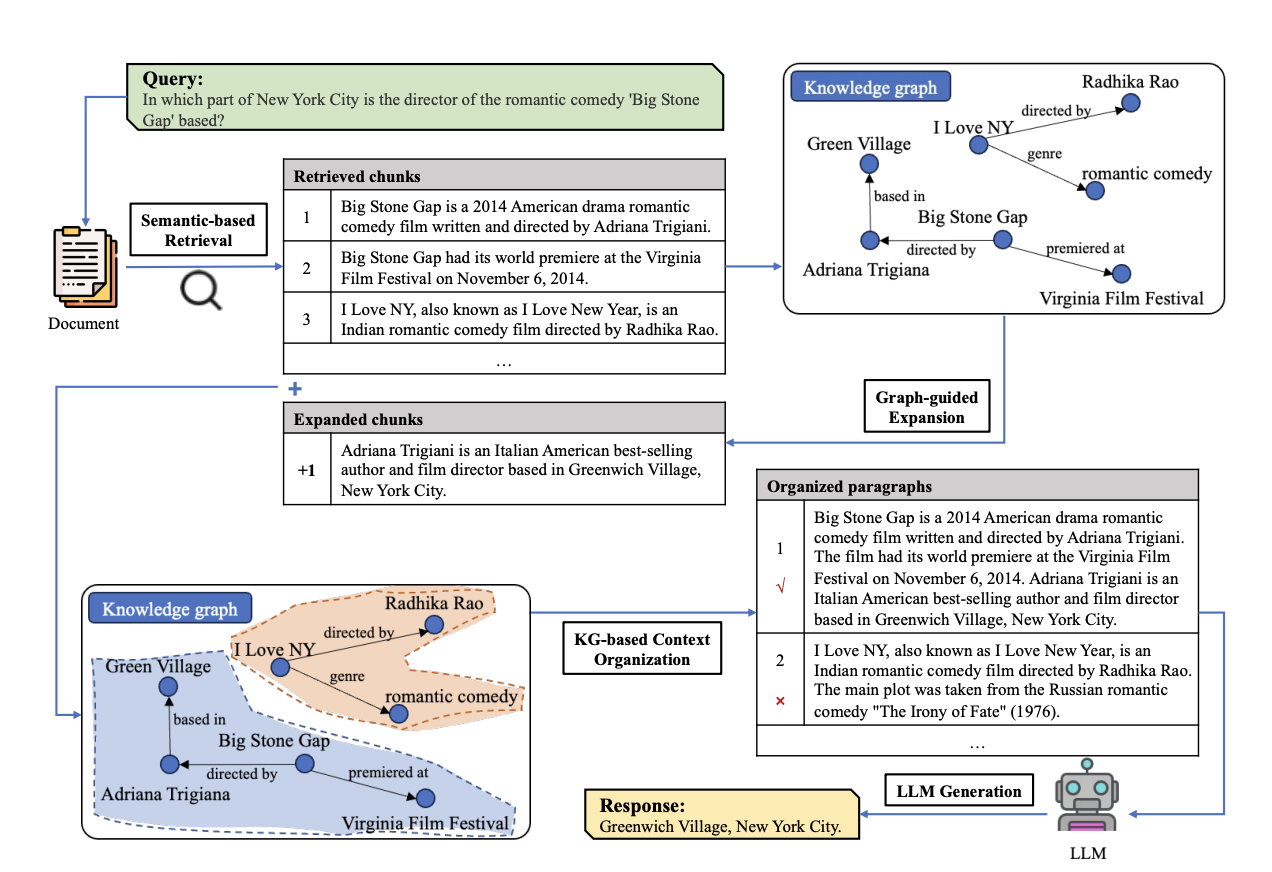

*Knowledge-graph-guided retrieval, from the session document.*

Read it from the top left. The **query** asks which part of New York City the director of the film *Big Stone Gap* is based in. Hidden inside it are two hops: the film is *directed by* someone, and that someone is *based in* a place. **Semantic retrieval** finds chunks that look related: the film and its director (Adriana Trigiani), its premiere, and a distractor about a different romantic comedy, *I Love NY*, by a different director. None of them says where Trigiani is based. A small **knowledge graph** built from those chunks makes the structure explicit as triples, (Big Stone Gap, directed by, Adriana Trigiani) and so on, and shows that a "based in" edge is missing. **Graph-guided expansion** fetches the missing fact: Trigiani is based in Greenwich Village. **KG-based organisation** keeps only the evidence on the path Big Stone Gap → directed by → Adriana Trigiani → based in → Greenwich Village, and drops the *I Love NY* distractor. The **LLM** reads the organised evidence and answers: Greenwich Village, New York City. Embeddings find things that *look* related; a graph gives *precise connections* you can follow.

Let us build a tiny graph for DilSeTrips. Gemini extracts triples from a few facts; ordinary code follows the paths that start at Prasad; and Gemini answers from those paths.

In [ ]:
triples_schema = {
    "title": "triples",
    "description": "Facts as (subject, relation, object) triples",
    "type": "object",
    "properties": {
        "triples": {
            "type": "array",
            "items": {
                "type": "object",
                "properties": {
                    "subject": {"type": "string"},
                    "relation": {"type": "string", "description": "A short verb phrase such as 'prefers' or 'located in'"},
                    "object": {"type": "string"},
                },
                "required": ["subject", "relation", "object"],
            },
        }
    },
    "required": ["triples"],
}
triple_llm = llm.with_structured_output(triples_schema)

facts = """Prasad prefers quiet hotels. Prasad's partner eats only vegetarian food.
Snow Valley Cottage is located in Old Manali. Snow Valley Cottage is quiet. Snow Valley Cottage serves vegetarian food.
Mall Road Grand is located in Manali. Mall Road Grand is noisy.
River Bend Homestay is located in Old Manali. River Bend Homestay serves vegetarian food."""

graph = triple_llm.invoke(
    "Extract every fact as a triple. Use the exact names of people and places as subjects.\n"
    "Normalise qualities to exactly one of these objects: quiet, noisy, vegetarian food.\n"
    "Use the relation 'wants' for what a person wants or needs.\n\n" + facts
)["triples"]
for triple in graph:
    print(f"({triple['subject']}) --{triple['relation']}--> ({triple['object']})")

Now follow the edges. Starting from Prasad, we collect the things he and his partner want, then look for hotels connected to *all* of them. This is the "User → prefers → Hilton → located in → London" reasoning, done over our own graph.

In [ ]:
def objects_of(subject):
    """Everything the graph connects to this subject, as (relation, object) pairs."""
    found = []
    for triple in graph:
        if triple["subject"].lower() == subject.lower():
            found.append((triple["relation"], triple["object"]))
    return found

def subjects_with(object_text):
    """Every subject that has an edge pointing to this object."""
    found = []
    for triple in graph:
        if triple["object"].lower() == object_text.lower():
            found.append(triple["subject"])
    return found

people = ["prasad", "prasad's partner"]
paths_text = ""
for relation, wanted in objects_of("Prasad") + objects_of("Prasad's partner"):
    for hotel in subjects_with(wanted):
        if hotel.lower() in people:
            continue                      # the people point at these qualities too; we want places
        line = f"Prasad (or partner) --{relation}--> {wanted} <-- {hotel}"
        paths_text = paths_text + line + "\n"
        print(line)

answer = llm.invoke("Using ONLY these graph paths, which hotel satisfies everything Prasad and his partner want? "
                    "Name the path that proves it.\n" + paths_text)
print("\n" + answer.text)

Only one hotel appears on both paths (quiet *and* vegetarian), and the answer can point to the exact edges that justify it. Notice the instruction "normalise qualities to exactly one of these objects". Without it, Gemini might write "quiet hotels" in one triple and "quiet" in another, and the paths would never meet. Deciding that two names mean the same node is called **entity resolution**, and it is a big part of why knowledge graphs are powerful but laborious to build, and why most LLM agents start with a vector store. We keep graphs at this overview level, as the session plan suggests; the rest of the session uses vectors.

## 4. Memory inside the agent loop

An AI agent is more than a model producing text. It is a goal-directed system that perceives its environment, reasons and plans, acts through tools, learns from feedback and, crucially, **remembers past experiences to improve future decisions**. That makes it a closed loop rather than a one-shot predictor:

**Perceive → Remember / recall → Think / plan → Act (with tools) → Observe the outcome → Update memory → repeat**

Imagine you are a personal librarian for Alex. On Monday Alex says "I like mystery novels", and you remember. On Wednesday Alex asks for a recommendation, and you pick a mystery because you remember. Next month Alex says "I want something different", and you suggest a thriller he has not read, because you remember what he already read. Without memory you would ask every detail from scratch, every time.

Most vanilla LLMs are librarians with no memory. They are **reactive**: they respond only to what is in the current request, and recall nothing unless you resend it. "Remind me what I scheduled yesterday." "I don't know. Can you tell me?" An agent with memory can **store** (keep track of interactions, decisions and facts), **categorise** (organise memories as tasks, preferences or context) and **recall** (bring the right memory back at the right time).

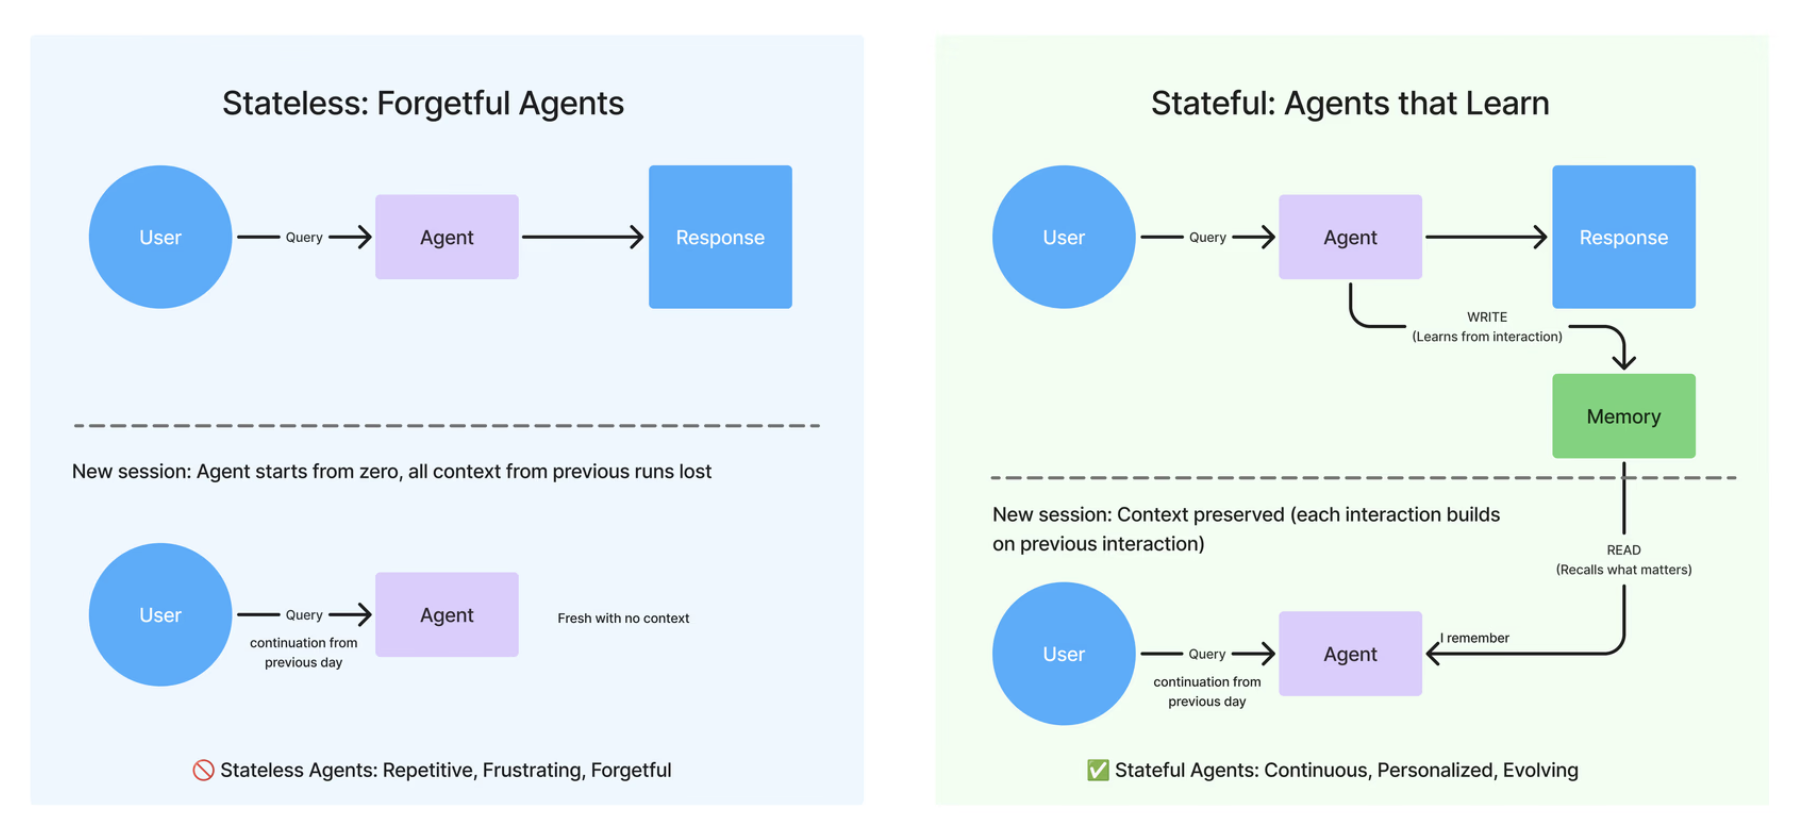

*Stateless agents start from zero every session. Stateful agents write what they learn to memory and read it back next time.*

### The kinds of memory

Think about your own brain: you can hold a phone number for a few seconds, recall your last birthday, know that Paris is the capital of France, and never forget how to ride a bike. Those are different kinds of memory serving different purposes, and LLM agents need the same variety.

- **Short-term (working) memory** is the scratchpad: it holds just enough for the current task or conversation.
- **Long-term memory** is the library: it persists after the conversation ends. It comes in three flavours: **episodic** (specific experiences and events), **semantic** (facts and concepts) and **procedural** (skills and how-to steps).

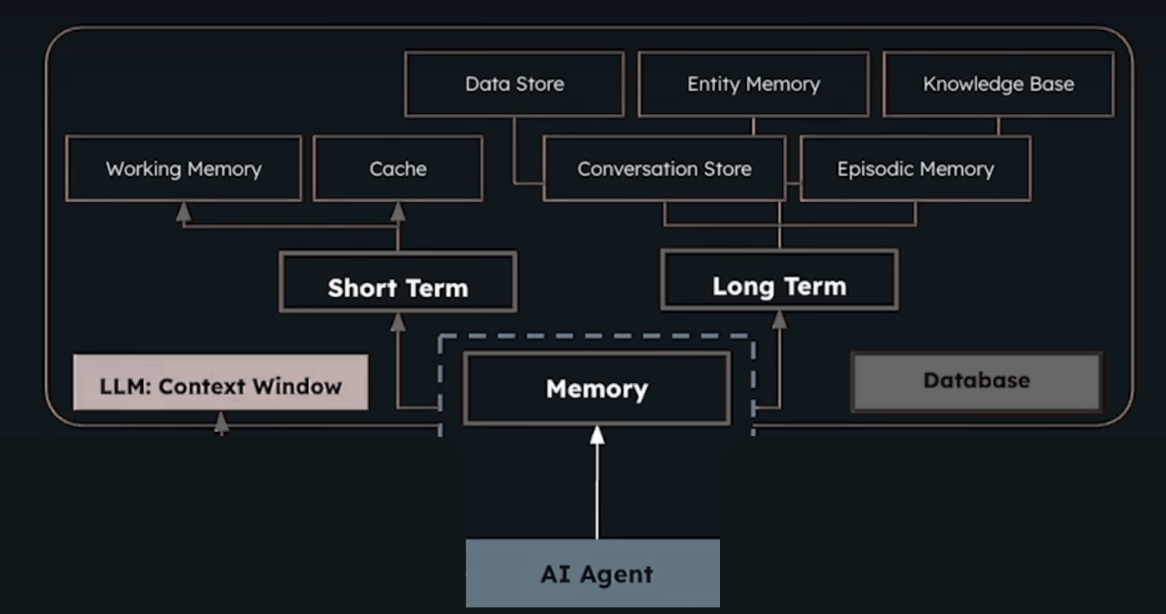

*Short-term memory lives in the LLM's context window; long-term memory lives in databases.*

We start with short-term memory, then move to long-term memory and its three flavours.

## 5. Short-term memory: the scratchpad (Ticket 1)

Imagine chatting with a support agent about new headphones: "My left earbud isn't connecting to Bluetooth." The agent must keep "left earbud" in mind to troubleshoot. Next you ask "What should I try first?" and it must still know it is the *left* earbud, or its advice makes no sense. Come back tomorrow in a fresh chat, though, and it has forgotten, because the detail lived only in short-term memory.

In an LLM agent, short-term memory is the **context window**: the limited scratchpad holding the most recent conversation. It is **volatile** (it lasts only for this session, or until the window overflows), **fast** (the model uses it instantly) and **limited** (pile on too much text and the oldest parts fall out). It is like remembering a phone number just long enough to dial it. Too small, and the agent forgets earlier parts of the chat; too big, and processing slows and costs rise.

Here is the conversation behind Ticket 1. Arjun and his wife Neha are planning a trip to Amritsar.

In [ ]:
conversation = [
    HumanMessage(content="Hi! My wife Neha and I want a 3-day trip to Amritsar next month. She's strictly vegetarian."),
    AIMessage(content="Lovely choice! Amritsar is wonderful for vegetarian food. How will you travel?"),
    HumanMessage(content="We'll take the train from Delhi. Which one is best?"),
    AIMessage(content="The Shatabdi Express is the most comfortable, about 6 hours from New Delhi."),
    HumanMessage(content="Suggest two hotels near the Golden Temple."),
    AIMessage(content="1) Heritage Haveli: Rs 3,200 a night, 5 minutes' walk. 2) City Comfort Inn: Rs 2,100 a night, 15 minutes' walk."),
    HumanMessage(content="What should we see on day 1?"),
    AIMessage(content="The Golden Temple at dawn, Jallianwala Bagh, then the Partition Museum."),
    HumanMessage(content="And day 2?"),
    AIMessage(content="The Wagah border ceremony in the afternoon; the old city bazaars in the morning."),
    HumanMessage(content="Is it cold there in December?"),
    AIMessage(content="Yes, nights drop to around 5 C and mornings can be foggy, so pack warm layers."),
]

from langchain_core.messages.utils import count_tokens_approximately

running_messages = []
for message in conversation:
    running_messages.append(message)
    role = type(message).__name__.replace("Message", "")     # "Human" or "AI"
    print(f"{len(running_messages):2d} messages, about {count_tokens_approximately(running_messages):4d} tokens   "
          f"{role:5s}: {message.content[:60]}")

Every turn adds to the tokens the model must read on the next call. Twelve short messages are tiny, but a real support chat or a trip-planning session with tool results can run to tens of thousands of tokens.

### 5.1 How big is the scratchpad?

The **context window is the upper bound of short-term memory**: it controls how much history the model can "see" at once. Short-term memory is really about *what fits inside the window and what gets cut off*. Think of it as working-memory bandwidth: you can keep five to seven things in mind, and when someone keeps talking, earlier items fall away. Four points matter beyond the basics.

**Overflow is not obvious.** Users assume the AI remembers the whole chat. If the conversation exceeds the limit, the earliest parts vanish silently. In a 4,000-token window, if the first 500 tokens held the user's preferences, they are literally invisible once pushed out.

**Compression is not the same as history.** Many systems summarise old text and reinsert the summary. But summaries lose detail, and can change meaning: "allergic to peanuts" summarised as "has food allergies" is no longer the same fact.

**Window size is not useful memory.** Bigger windows also keep irrelevant material visible, which can distract the model: a support bot with a huge window might bring up a two-month-old device issue when you are asking about billing. Research has also found that models use information at the start and end of a long context more reliably than information buried in the middle (the "lost in the middle" effect).

**In practice,** what feels like ChatGPT or Gemini "remembering you" within a chat is usually just the context window plus session history. Frameworks such as LangChain combine retrieval with short-term context because relying on the raw window alone is brittle.

### 5.2 Forgetting by overflow

LLMs do not forget like people, gradually and fuzzily. Forgetting is **structural and sudden**: once the conversation exceeds the window, the oldest tokens are cut. Picture a whiteboard: when it fills, you erase from the top and keep writing at the bottom, and whatever was erased is gone.

Its features: it is a **hard cut-off** (a token is either 100% visible or 0%); it is **invisible to the user** (the model never says "I forgot"); it **breaks coherence** (if "allergic to penicillin" drops out, an AI might later recommend penicillin); and it is usually **mitigated by summarising or storing old context** in a vector database, which brings its own distortions. Early free-tier ChatGPT had about 4,000 tokens; after 15 to 20 messages, earlier parts disappeared silently. Telecom and banking bots ask you to restate your problem in long chats for the same reason.

Let us reproduce Ticket 1. We give the model only the last four messages, as a small window would, then ask for dinner.

**Before you run it:** will the windowed version remember that Neha is vegetarian?

In [ ]:
from langchain_core.messages import trim_messages

probe = ("Suggest one dinner place for us tonight in Amritsar, and remind me exactly how much "
         "the first hotel you suggested costs per night. Two sentences.")

# A small window: only the last 4 messages fit (token_counter=len counts messages instead of tokens)
small_window = trim_messages(conversation, max_tokens=4, token_counter=len, strategy="last", start_on="human")
print(f"The small window keeps {len(small_window)} of {len(conversation)} messages, starting with: {small_window[0].content!r}\n")

reply_window = llm.invoke(small_window + [HumanMessage(content=probe)])
reply_full = llm.invoke(conversation + [HumanMessage(content=probe)])

print("With only the last 4 messages:\n", reply_window.text, "\n")
print("With the whole conversation:\n", reply_full.text)

With the small window, the model has no idea Neha is vegetarian or what the hotel cost, so it guesses or recommends something unsuitable: Ticket 1 exactly. With the full conversation, it gets both right. Nothing was "ignored": the facts were simply not in the prompt.

### 5.3 The trade-offs of window size

| | Small window | Large window |
|---|---|---|
| Advantages | Cheaper and faster (fewer tokens per call); less noise; easy to debug, since you know what the model sees | Longer coherence without summarising; critical details less likely to be dropped; feels like the AI really remembers |
| Drawbacks | Forgets older but relevant details; users must repeat themselves; long tasks (tutoring, troubleshooting) lose the thread | Every token costs money, even greetings; slower responses; more irrelevant detail to distract the model |
| Example | A banking bot with a 2,000-token window forgets your account type halfway through a 20-message session | Feeding 200 pages of raw logs to a support agent does not guarantee better answers; it may latch onto an irrelevant line |

Think of a backpack. A small one is light but forces you to leave useful things behind. A huge one fits everything but slows you down and buries what you need. Smart travellers pack the essentials and put the rest in checked luggage: that is a **hybrid** of short-term and long-term memory.

### 5.4 Forgetting and prioritising within the window

Even inside the window, an agent must decide what stays active.

**The eviction problem.** When the window fills, what goes first? **Naive eviction (FIFO)** drops the oldest text: simple and predictable, but it may discard relevant details. **Relevance-aware eviction** scores messages and keeps the important ones while dropping small talk: better context, but extra computation. After 100 turns of a support chat, "hello, how's your day?" should go, not your account ID.

**Summarisation instead of dropping.** Compress old dialogue into a short gist and keep that. It saves space and preserves meaning, but summaries can distort or hallucinate if not checked. A therapy bot might keep "User is stressed about work deadlines and anxious about a presentation" instead of an hour of messages.

**Relevance and importance scoring.** Agents score what to keep by **recency** (newer is usually more relevant), **similarity** (how close a past message is to the current question, by embeddings) and **importance** (flags set by developers or users, such as allergies). "Nice weather today" scores low and is dropped; "user has a peanut allergy" scores high and is always kept, or promoted to long-term memory.

**Forgetting is not always bad.** Dropping irrelevant details prevents noise, keeps costs manageable and stops the agent repeating old material, just as you keep formulas and key ideas from a textbook, not every sentence.

So short-term memory works best when it **forgets small talk, summarises older context, and always keeps critical facts**.

### 5.5 Five strategies, built in code

LangChain used to offer five ready-made memory classes for this, and many tutorials (and the session document) still describe them: `ConversationBufferMemory`, `ConversationBufferWindowMemory`, `ConversationSummaryMemory`, `ConversationSummaryBufferMemory` and `ConversationEntityMemory`. In LangChain 1.x they are deprecated and have moved to the legacy `langchain-classic` package. The ideas are what matter, and each takes only a few lines to build yourself.

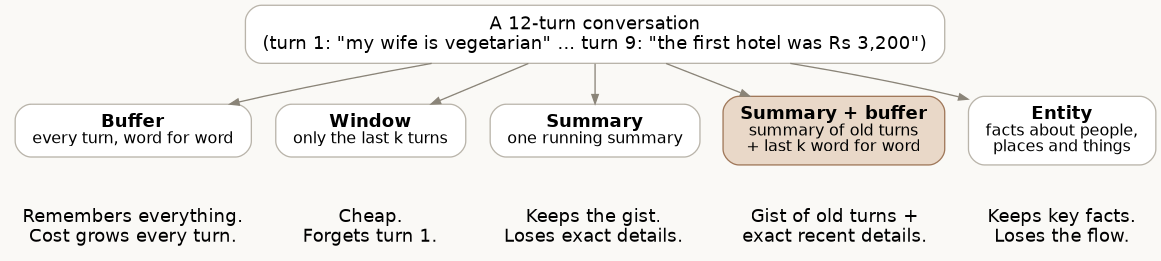

*What each strategy keeps from the same conversation.*

We give all five the same question, the one Ticket 1 failed on: what can Neha eat, and exactly what did the first hotel cost?

In [ ]:
def transcript(messages):
    """Turn a list of messages into plain text, for summarising."""
    text = ""
    for message in messages:
        if type(message).__name__ == "HumanMessage":
            text = text + "User: " + message.content + "\n"
        else:
            text = text + "Assistant: " + message.content + "\n"
    return text

memories_to_test = {}

# 1. Buffer: everything, word for word
memories_to_test["Buffer"] = conversation

# 2. Window: only the last 4 messages
memories_to_test["Window (last 4)"] = small_window

# 3. Summary: one running summary instead of the transcript
# TODO: HW2 [Medium] - Add "Neha has a peanut allergy" to turn 1 and re-run. Does the summary keep it word for word, or
# soften it? How would you make sure facts marked as critical are never summarised away?
summary = llm.invoke("Summarise this conversation in under 50 words, for your own memory:\n" + transcript(conversation)).text
memories_to_test["Summary"] = [SystemMessage(content="Summary of the conversation so far: " + summary)]

# 4. Summary + buffer: a summary of the older part, plus the last 4 messages word for word
older_summary = llm.invoke("Summarise this conversation in under 50 words, for your own memory:\n" + transcript(conversation[:-4])).text
memories_to_test["Summary + buffer"] = [SystemMessage(content="Summary of earlier conversation: " + older_summary)] + small_window

# 5. Entity: facts about people, places and things
entity_schema = {
    "title": "entities",
    "description": "Facts about each person, place or thing mentioned",
    "type": "object",
    "properties": {"entities": {"type": "array", "items": {"type": "object", "properties": {
        "name": {"type": "string"}, "facts": {"type": "array", "items": {"type": "string"}}},
        "required": ["name", "facts"]}}},
    "required": ["entities"],
}
entities = llm.with_structured_output(entity_schema).invoke(
    "List the key facts about each person, place or thing in this conversation:\n" + transcript(conversation))["entities"]
entity_text = ""
for entity in entities:
    entity_text = entity_text + f"- {entity['name']}: " + "; ".join(entity["facts"]) + "\n"
memories_to_test["Entity"] = [SystemMessage(content="Known facts:\n" + entity_text)]

print("Summary:", summary)
print("\nEntities:\n" + entity_text)

Read the summary and the entity list before going on. Did the summary keep the price "Rs 3,200", or just "two hotels"? Did the entity list keep "strictly vegetarian"? Now the test.

In [ ]:
print(f"{'Strategy':18s} {'Tokens sent':>11s}  {'Vegetarian?':>11s}  {'Rs 3,200?':>9s}")
for label in memories_to_test:
    memory_messages = memories_to_test[label]
    reply = llm.invoke(memory_messages + [HumanMessage(content=probe)])
    answer = reply.text.lower()
    mentions_veg = "vegetarian" in answer or "veg " in answer or "pure veg" in answer
    mentions_price = "3,200" in answer or "3200" in answer
    tokens = count_tokens_approximately(memory_messages)
    print(f"{label:18s} {tokens:11d}  {str(mentions_veg):>11s}  {str(mentions_price):>9s}")
    memories_to_test[label] = {"messages": memory_messages, "answer": reply.text}

A typical run: the **buffer** gets both right and sends the most tokens. The **window** sends the fewest and gets neither. The **summary** usually keeps "vegetarian" but often loses the exact price. **Summary plus buffer** keeps the gist of the old part and the recent details. The **entity** memory keeps both facts as facts, but has lost the flow: it could not tell you what was said in which order. (The True/False columns are simple text checks; read a couple of the answers in `memories_to_test` to confirm them.)

| Strategy | Good at | Weak at | Use it when |
|---|---|---|---|
| Buffer | Exact recall of everything ("what was the first formula you explained?") | Grows forever; slow and expensive in long sessions | Short conversations |
| Window | Light and fast; recent turns only | Cannot recall anything older ("what did we discuss yesterday?") | Only the last few exchanges matter |
| Summary | Long-term continuity in few tokens | Loses exact details ("what exact equation did you give me?") | Long sessions where the gist is enough |
| Summary + buffer | Gist of old turns plus exact recent turns | Still does not track facts about entities | The usual default for chat agents |
| Entity | Remembers facts about people and things ("who is my professor?") | Loses the flow of conversation | Personalisation; facts that must survive |

None of these survives the end of the session. For that we need long-term memory.

## 6. Long-term memory: the full lifecycle (Tickets 2 and 5)

Short-term memory is fast, volatile and session-bound. Once the session ends, everything is gone, which is Ticket 2: Prasad has told DilSeTrips where he lives four times. **Long-term memory** is persistent: the agent's notebook, diary and library in one, kept across sessions.

Long-term memory is not magic. It is a system of storage, retrieval and integration, a smart filing system with six operations:

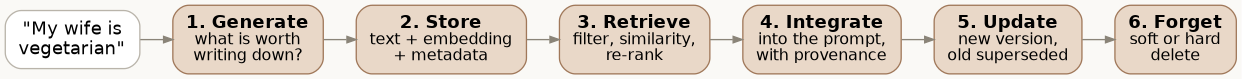

*Every long-term memory goes through these six stages.*

We build each stage as a small function, on a vector store with **metadata**. Every memory records who it belongs to, what kind it is, how important it is, how confident we are, the exact words it came from, when it was stored, its status and its version.

### 6.1 Generate: deciding what is worth writing down

When the user says something, the system decides whether it is worth saving, and if so, in what form: raw text, a short summary or a structured field. In practice that means **extraction rules** (keyword rules for things like "allergic", plus LLM-based extraction), **summarisation** of long chats into short facts, and an **embedding** of each fact for later search.

The pitfalls: **over-capture** (saving every sentence makes a noisy store), **under-capture** (saving only trivia means forgetting what matters) and **no provenance** (a fact with no source cannot be checked later). So we tag every memory with its source, confidence and timestamp.

Our extractor is an LLM with structured output and strict rules. The rules matter a great deal, as Ticket 3 will show.

In [ ]:
memory_schema = {
    "title": "memories",
    "description": "Facts worth remembering from a user's message",
    "type": "object",
    "properties": {"memories": {"type": "array", "items": {"type": "object", "properties": {
        "text": {"type": "string", "description": "One self-contained fact in the third person, e.g. 'Prasad lives in Pune.'"},
        "kind": {"type": "string", "enum": ["semantic", "episodic", "procedural"]},
        "importance": {"type": "integer", "description": "1 (trivia) to 5 (critical, e.g. dietary needs, allergies)"},
        "confidence": {"type": "number", "description": "0 to 1: how sure you are that this is true"},
        "source_quote": {"type": "string", "description": "The exact words in the message that support this fact"},
    }, "required": ["text", "kind", "importance", "confidence", "source_quote"]}}},
    "required": ["memories"],
}
memory_llm = llm.with_structured_output(memory_schema)

careful_rules = ("You decide what a travel concierge should remember about a user. Extract only facts the user "
                 "EXPLICITLY stated. Never guess or infer health conditions, religion, income or anything not said. "
                 "Never store card numbers, passwords, OTPs or ID numbers. Skip small talk. "
                 "Return an empty list if nothing is worth remembering.")

def generate_memories(user_name, message, rules=careful_rules):
    return memory_llm.invoke(rules + f"\nThe user's name is {user_name}.\nMessage: {message}")["memories"]

todays_message = "Hi again! We live in Pune, by the way. We'd love a relaxed weekend getaway we can drive to. Lovely weather today, isn't it?"
new_memories = generate_memories("Prasad", todays_message)
for memory in new_memories:
    print(json.dumps(memory, ensure_ascii=False))

The extractor should keep "Prasad lives in Pune" and the wish for a drivable weekend getaway, and skip the weather small talk. Every memory carries the exact words it came from.

### 6.2 Store: filing it in the right folder

Text and embedding go into a **vector database** for semantic search; metadata (user, date, tags, consent) goes alongside for fast filtering. Think of the embedding as a fingerprint of the meaning. Good practice: keep raw logs in cheap "cold" storage for auditing and condensed memories in fast "hot" storage; separate users with **namespaces** so their memories can never mix; encrypt at rest and in transit. Pitfalls: raw personal data stored unprotected, everything in one big index, and no provenance.

Our store is the same in-memory vector store as last session. To make recency meaningful, we first add a few memories "from earlier sessions", dated some days in the past, for two users: Prasad, and Arjun from Ticket 1.

In [ ]:
from langchain_core.vectorstores import InMemoryVectorStore

# TODO: HW3 [Medium] - This store lives in memory and vanishes when the notebook restarts. Move it to your Pinecone index with one
# namespace per user, reading the embedding dimension from the index. Is the user filter in retrieve_memories still needed?
memory_store = InMemoryVectorStore(embedding=embeddings)
memory_counter = {"next": 1}

def store_memory(user_id, text, kind, importance, confidence, source_quote, days_ago=0, version=1, supersedes=""):
    memory_id = f"mem-{memory_counter['next']}"
    memory_counter["next"] = memory_counter["next"] + 1
    metadata = {
        "memory_id": memory_id, "user_id": user_id, "kind": kind, "importance": importance,
        "confidence": confidence, "source_quote": source_quote,
        "stored_on": (date.today() - timedelta(days=days_ago)).isoformat(),
        "status": "active", "version": version, "supersedes": supersedes,
    }
    memory_store.add_texts([text], metadatas=[metadata], ids=[memory_id])
    return memory_id

# Memories from earlier sessions (written here by hand, dated in the past)
store_memory("prasad", "Prasad's partner is vegetarian.", "semantic", 5, 1.0, "she's vegetarian", days_ago=40)
store_memory("prasad", "Prasad gets motion sickness on long bus rides.", "semantic", 4, 1.0, "I get sick on long bus rides", days_ago=40)
store_memory("prasad", "Prasad prefers window seats on flights.", "semantic", 2, 0.9, "window seat please", days_ago=120)
store_memory("prasad", "Prasad once asked about beach shacks in Goa.", "episodic", 1, 0.8, "any good beach shacks in Goa?", days_ago=200)
store_memory("arjun", "Arjun's wife Neha is strictly vegetarian.", "semantic", 5, 1.0, "She's strictly vegetarian", days_ago=10)
store_memory("arjun", "Arjun prefers trains to flights.", "semantic", 3, 1.0, "We'll take the train", days_ago=10)

# Today's memories, from the extractor
for memory in new_memories:
    store_memory("prasad", memory["text"], memory["kind"], memory["importance"], memory["confidence"], memory["source_quote"])

def all_memories():
    return memory_store.get_by_ids(list(memory_store.store.keys()))

def memories_of_user_active(user_id):
    found = []
    for document in all_memories():
        if document.metadata["user_id"] == user_id and document.metadata["status"] == "active":
            found.append(document)
    return found

for document in all_memories():
    meta = document.metadata
    print(f"{meta['memory_id']:7s} {meta['user_id']:7s} {meta['kind']:9s} imp {meta['importance']}  {meta['stored_on']}  {document.page_content}")

### 6.3 Retrieve: finding the right memories

Retrieval runs in four steps: **pre-filter** by metadata (this user, active memories only) to narrow the candidates; **similarity search** on embeddings for the top matches; **re-rank** them; **return** the best few to the LLM. Two choices matter. **k**, how many to fetch: too few may miss context, too many confuse the model. And the **score**. Similarity alone favours whatever sounds closest, however old or trivial; the session document suggests combining similarity, recency and importance:

$$\text{score} = 0.6 \times \text{similarity} + 0.3 \times \text{recency} + 0.1 \times \text{importance}$$

We define recency as $1 / (1 + \text{days old} / 30)$, so a memory from today scores 1.0 and one from a month ago scores 0.5, and importance as the 1-to-5 rating divided by 5. Every number is printed so you can follow the arithmetic. Monitor retrieval in production with recall@k on known questions, latency, and how often users say "no, that's wrong".

In [ ]:
def rank_by_score(scored):
    """Sort a list of dictionaries by their 'score', highest first (selection sort, so no extra tools are needed)."""
    remaining = list(scored)
    ranked = []
    while len(remaining) > 0:
        best = remaining[0]
        for item in remaining:
            if item["score"] > best["score"]:
                best = item
        ranked.append(best)
        remaining.remove(best)
    return ranked

def retrieve_memories(user_id, query, k=3, show_working=True):
    # TODO: HW1 [Easy] - These weights (0.6, 0.3, 0.1) are a starting point, not a law. Find a question where an old but
    # important memory loses to a new trivial one. Which weight would you change, and what could go wrong if you overdo it?
    def is_this_users_active_memory(document):
        return document.metadata["user_id"] == user_id and document.metadata["status"] == "active"

    candidates = memory_store.similarity_search_with_score(query, k=8, filter=is_this_users_active_memory)
    scored = []
    for document, similarity in candidates:
        days_old = (date.today() - date.fromisoformat(document.metadata["stored_on"])).days
        recency = 1 / (1 + days_old / 30)
        importance = document.metadata["importance"] / 5
        score = 0.6 * similarity + 0.3 * recency + 0.1 * importance
        scored.append({"document": document, "score": score,
                       "working": f"0.6x{similarity:.2f} + 0.3x{recency:.2f} + 0.1x{importance:.2f} = {score:.3f}"})
    ranked = rank_by_score(scored)
    if show_working:
        print(f"Query: {query}")
        for item in ranked:
            print(f"   {item['working']}   {item['document'].page_content}")
    return ranked[:k]

top_memories = retrieve_memories("prasad", "Plan a relaxed weekend getaway for us")

Look at how the three parts trade off. The Pune memory is fresh (recency 1.0) and relevant. The vegetarian memory is 40 days old but important (1.0), so it stays near the top. The Goa beach-shack question is 200 days old and trivial, so even if it sounds holiday-like, it sinks. Arjun's memories never appear at all: the pre-filter removed them before similarity was even computed.

### 6.4 Integrate: using memories in the answer

Two patterns are common. **Context-append** places the retrieved memories in the prompt. **Template-driven** answers fill a fixed template from structured facts, which is safer in high-risk domains. Watch three things: the **token budget** (too many long memories overflow the window), **provenance** (tell the user where a fact came from: "because you told me on Aug 2"), and **confidence** (if a memory is uncertain, ask before relying on it). Never use memories blindly in critical domains like medicine, and do not send sensitive memory text to third-party APIs without redaction.

Now Ticket 2: a brand-new session, with and without long-term memory.

In [ ]:
def memory_context(ranked_memories):
    text = ""
    for item in ranked_memories:
        meta = item["document"].metadata
        line = f"- {item['document'].page_content} (from the user's words on {meta['stored_on']}: \"{meta['source_quote']}\")"
        if meta["confidence"] < 0.6:
            line = line + " [unconfirmed: ask before relying on this]"
        text = text + line + "\n"
    return text

new_session_question = "Suggest a weekend getaway for us. Keep it to three sentences."

without_memory = llm.invoke(new_session_question)
with_memory = llm.invoke([
    SystemMessage(content="You are DilSeTrips. What you remember about this user:\n" + memory_context(top_memories)
                          + "Use these memories, and mention the one that most shaped your suggestion."),
    HumanMessage(content=new_session_question),
])
print("WITHOUT long-term memory:\n", without_memory.text, "\n")
print("WITH long-term memory:\n", with_memory.text)

Without memory, the model asks where they live, or suggests somewhere arbitrary: Ticket 2. With memory, it suggests a drive from Pune (Lonavala, Mahabaleshwar or similar), keeps the food vegetarian, and says which memory shaped the answer. That last part is provenance, and it lets users catch wrong memories.

### 6.5 Update: keeping memories current

People change their preferences, addresses and medical conditions, and memory must follow. The strategies: **append and version** (keep the old version, write a new one, and mark the old one superseded; best for audits); **overwrite** (only for unimportant, outdated facts); and **regenerate derived summaries** when the facts under them change. The classic pitfall is updating a fact but not the summaries built from it, which then keep giving stale advice.

Prasad has news.

In [ ]:
def update_memory(old_memory_id, new_text, source_quote):
    old_document = memory_store.get_by_ids([old_memory_id])[0]
    old_meta = dict(old_document.metadata)
    old_meta["status"] = "superseded"
    memory_store.add_texts([old_document.page_content], metadatas=[old_meta], ids=[old_memory_id])   # same id: replaces it
    return store_memory(old_meta["user_id"], new_text, old_meta["kind"], old_meta["importance"], 1.0, source_quote,
                        version=old_meta["version"] + 1, supersedes=old_memory_id)

new_fact = "Prasad lives in Bengaluru."
new_quote = "We just moved to Bengaluru"

# Which existing memory does the new fact replace? Similarity alone can pick the wrong one, so we ask Gemini.
active_list = ""
for document in memories_of_user_active("prasad"):
    active_list = active_list + f"{document.metadata['memory_id']}: {document.page_content}\n"

replace_schema = {"title": "replacement", "description": "Which memory a new fact replaces", "type": "object",
                  "properties": {"replaces_memory_id": {"type": "string", "description": "The id, or 'none'"},
                                 "reason": {"type": "string"}},
                  "required": ["replaces_memory_id", "reason"]}
decision = llm.with_structured_output(replace_schema).invoke(
    f"New fact: {new_fact}\nExisting memories:\n{active_list}\n"
    "Which single existing memory does the new fact make out of date? Answer with its id, or 'none'.")
print("Gemini's decision:", decision)

# TODO: HW4 [Medium] - What should happen when Gemini answers 'none', or names an id that does not exist, or picks the wrong
# memory? Add those checks, and a step that asks the user to confirm before an important memory is replaced.
new_id = update_memory(decision["replaces_memory_id"], new_fact, new_quote)
print("New version:", new_id, "\n")

for document in all_memories():
    if document.metadata["user_id"] == "prasad" and "live" in document.page_content:
        meta = document.metadata
        print(f"{meta['memory_id']:7s} v{meta['version']} {meta['status']:10s} supersedes='{meta['supersedes']}'  {document.page_content}")

Both versions still exist, so you can audit when and why the fact changed, but only the active one can be retrieved.

### 6.6 Forget and delete: Ticket 5

Two forms of deletion. A **soft delete** marks a memory deleted, so it is excluded from retrieval but still stored. A **hard delete** removes the text *and* the embedding, which strict privacy laws require. Delete when the user asks, when a retention period expires (say, working context older than 30 days), or when a memory turns out to be wrong. And **cascade**: if a summary was built from a deleted memory, invalidate or regenerate it. The classic pitfalls are forgetting to delete the embedding (it can still be retrieved), and relying on soft deletes only, so the raw data remains for an auditor or attacker to find.

Arjun asked us to delete everything. First a soft delete, then a hard one.

In [ ]:
def memories_of(user_id):
    found = []
    for document in all_memories():
        if document.metadata["user_id"] == user_id:
            found.append(document)
    return found

# Soft delete: mark as deleted (still stored)
for document in memories_of("arjun"):
    meta = dict(document.metadata)
    meta["status"] = "deleted"
    memory_store.add_texts([document.page_content], metadatas=[meta], ids=[meta["memory_id"]])
print("After soft delete:", len(memories_of("arjun")), "of Arjun's memories are still stored (marked deleted).")

# Hard delete: remove text AND embedding
# TODO: HW5 [Hard] - If a trip summary had been built from Arjun's memories, it would still contain his data after this.
# How would you track which summaries depend on which memories, so a delete can find and regenerate them?
arjun_ids = []
for document in memories_of("arjun"):
    arjun_ids.append(document.metadata["memory_id"])
memory_store.delete(ids=arjun_ids)

print("After hard delete:", len(memories_of("arjun")), "of Arjun's memories remain.")
print("Can his memory still be found by id?", len(memory_store.get_by_ids(arjun_ids)) > 0)
print("Total memories left in the store:", len(memory_store.store))

### The lifecycle at a glance

| Stage | Simple idea | What happens | Best practices | Common pitfalls |
|---|---|---|---|---|
| 1. Generate | Decide what is worth writing down | Extract facts by rules or LLM; summarise; embed | Save structured and raw text; add timestamp and provenance | Over-capture, under-capture, no provenance |
| 2. Store | File notes in the right folder | Text and embedding in a vector store, metadata alongside | Cold raw logs and hot condensed memories; per-user namespaces; encryption | Mixing users; raw personal data unprotected |
| 3. Retrieve | Search your notes | Filter, similarity search, re-rank, top-k | Balance k; combine similarity, recency and importance | Stale or irrelevant results; slow at scale |
| 4. Integrate | Ground the answer in the notes | Append to the prompt or fill a template | Show provenance; manage tokens; ask when unsure | Overloading context; trusting memory blindly |
| 5. Update | Keep notes fresh | New version; old one superseded; summaries regenerated | Append-only logs; periodic consolidation | Overwriting history; stale summaries |
| 6. Delete | Throw notes away when asked or expired | Soft delete (flag) or hard delete (text and embedding) | Honour requests; cascade to summaries | Embedding left behind; soft delete only |

## 7. Forgetting at scale: three strategies

In large systems you cannot keep everything forever. Memory costs storage, slows retrieval, and lingering old data is a privacy risk. So large-scale apps use deliberate **forgetting strategies**.

**1. Periodical (time-based) deletion.** Each memory has a usage count. If a memory used often in the past is now used much less, so its usage drops below a threshold, delete it, like clearing out clothes you have not worn in months. Its weakness: it looks only at recency and frequency, not usefulness. A recent memory can be useless, and an old one can still be valuable.

**2. History-based (utility) deletion.** A memory must have been used at least *n* times before it is considered. Then check its **average usefulness** across those uses, and delete it if usefulness is low, like uninstalling an app you open often but which crashes every time. Its weakness: it can keep old but useful memories forever, even if they are never used again.

**3. Combined deletion.** Delete only when *both* agree: it has gone stale **and** it was not useful. Like a wardrobe clear-out: you have not worn the shirt in ages, *and* it never looked good. This is usually the most practical choice at scale.

Utility-based forgetting needs a usefulness signal. In production, one source is an **LLM judge** that rates whether each retrieved memory actually helped the answer, the same idea as Session 8's evaluation. We generate one round of ratings now for the memories behind the getaway answer, and add them to some usage statistics. **The usage counts and earlier ratings below are illustrative numbers**, standing in for a month of real traffic.

In [ ]:
usage_stats = {
    "Prasad's partner is vegetarian.":            {"uses_previous_month": 14, "uses_this_month": 12, "usefulness": [0.9, 1.0, 0.8]},
    "Prasad gets motion sickness on long bus rides.": {"uses_previous_month": 6, "uses_this_month": 5, "usefulness": [0.7, 0.9, 0.8]},
    "Prasad prefers window seats on flights.":    {"uses_previous_month": 8, "uses_this_month": 1, "usefulness": [0.8, 0.7, 0.9]},
    "Prasad once asked about beach shacks in Goa.": {"uses_previous_month": 9, "uses_this_month": 1, "usefulness": [0.1, 0.2, 0.0]},
}

ratings_schema = {
    "title": "memory_ratings",
    "description": "How useful each memory was for the answer",
    "type": "object",
    "properties": {"ratings": {"type": "array", "items": {"type": "object", "properties": {
        "memory": {"type": "string"}, "usefulness": {"type": "number", "description": "0 (no help) to 1 (essential)"}},
        "required": ["memory", "usefulness"]}}},
    "required": ["ratings"],
}
memory_list = ""
for memory_text in usage_stats:
    memory_list = memory_list + "- " + memory_text + "\n"

ratings = llm.with_structured_output(ratings_schema).invoke(
    f"A travel concierge answered: {new_session_question}\nAnswer: {with_memory.text}\n\n"
    f"For each memory below, rate how useful it was (or would have been) for this answer. Copy each memory exactly.\n{memory_list}"
)["ratings"]

for rating in ratings:
    if rating["memory"] in usage_stats:
        usage_stats[rating["memory"]]["usefulness"].append(rating["usefulness"])
        print(f"judge: {rating['usefulness']:.1f}  {rating['memory']}")

In [ ]:
# TODO: HW6 [Easy] - Change the thresholds below (0.3 for the usage drop, 0.4 for usefulness, 3 for minimum uses). Which memory
# changes its fate first? What would a too-aggressive setting do to a user who travels only once a year?
drop_threshold = 0.3        # periodical: delete if this month's use is below 30% of last month's
usefulness_threshold = 0.4  # history: delete if average usefulness is below 0.4 ...
minimum_uses = 3            # ... once it has been rated at least 3 times

def verdict(should_delete):
    if should_delete:
        return "DELETE"
    return "keep"

print(f"{'Memory':48s} {'use ratio':>9s} {'avg useful':>10s}  periodical  history  combined")
for memory_text in usage_stats:
    stats = usage_stats[memory_text]
    use_ratio = stats["uses_this_month"] / stats["uses_previous_month"]
    total = 0
    for value in stats["usefulness"]:
        total = total + value
    average_usefulness = total / len(stats["usefulness"])

    periodical = use_ratio < drop_threshold
    history = len(stats["usefulness"]) >= minimum_uses and average_usefulness < usefulness_threshold
    combined = periodical and history

    print(f"{memory_text[:48]:48s} {use_ratio:9.2f} {average_usefulness:10.2f}  "
          f"{verdict(periodical):10s}  {verdict(history):7s}  {verdict(combined)}")

The window-seat memory shows why the combined strategy exists. Its usage dropped sharply this month (Prasad has not flown), so periodical deletion would throw it away, yet every time it was used it was useful. The utility check saves it. The Goa beach-shack memory is both stale and useless, so all three strategies agree to delete it.

**A note on what "delete" means in big consumer apps.** In apps like Google Photos, YouTube, Spotify or Netflix, forgetting usually does **not** mean deletion. It means *lowering surfacing priority*: the system stops showing you old or irrelevant things, but keeps the data, because data improves recommendation models and analytics. True deletion often happens only when privacy laws require it, as with Google Maps' auto-delete for location history. When you build agents, decide deliberately which kind of forgetting you are promising users, and keep that promise.

## 8. Three kinds of long-term memory (Ticket 4)

Not all memories are alike. Some are **facts** about the world, some are **experiences** we went through, and some are **skills** we learned. Cognitive science calls these semantic, episodic and procedural memory, and agent design borrows the same split.

### 8.1 Semantic memory: the encyclopedia

Semantic memory stores **general, factual knowledge**: concepts, facts and relationships that do not depend on a particular event. It is impersonal and objective, the agent's mental encyclopedia, used for answering questions, understanding language and making deductions. It works in three stages. **Encoding** acquires and structures facts, identifying entities ("Paris", "Eiffel Tower"), attributes ("is a city") and relationships ("Paris is the capital of France"). **Storage** organises them, often in a knowledge graph of nodes and edges, independent of where each fact was first learned. **Retrieval** follows the structure to answer: "What is the capital of France?" goes France → has capital → Paris.

You have built semantic memory twice already: the triples in Chapter 3, and memories like "Prasad's partner is vegetarian" in Chapter 6. A large part of an LLM's general knowledge is semantic memory stored in its weights; the facts we store add knowledge *about this user* that the weights could never contain.

### 8.2 Episodic memory: the diary

Episodic memory lets us recall and mentally re-live **specific events** from our own past: the *what*, *where* and *when*. Psychologist Endel Tulving introduced the term to distinguish it from semantic memory (facts) and procedural memory (skills). Semantic memory tells you Paris is the capital of France; episodic memory lets you recall *your* trip to Paris, what you saw and how you felt.

It works in three stages. **Encoding** captures the experience with its context: the taste of a new dish, the place, the people with you. A personal assistant might encode that you like morning coffee reminders, or your usual route to work. **Storage (consolidation)** makes it last. Human memories are not fixed; they are updated and reinforced over time, and a fitness app might consolidate which exercises you prefer and where you do them. **Retrieval** brings it back when a cue appears: the smell of fresh bread recalling a grandmother's kitchen, or a support bot recalling your previous complaint to resolve a new one faster, or a tutor recalling that you struggled with fractions last week.

For AI systems, episodic memory supports five things:

| Use | How episodes help | Examples |
|---|---|---|
| Planning | Past sequences become templates for new ones | Assistants proposing task orders from past schedules; route planners recalling past trips; supply chains recalling seasonal demand |
| Imagination and prediction | Similar past episodes simulate likely futures | Marketing predicting preferences; healthcare anticipating follow-ups; smart homes predicting energy use |
| Problem solving | Solutions that worked before are adapted | Support bots reusing past tickets; robots adapting assembly sequences |
| Decision making | Past outcomes estimate the value of choices | Recommenders; investment analysis from past market episodes; game strategy |
| Learning from experience | Episodes are re-read and refined as new data arrives | Tutors adapting to past errors; predictive maintenance learning from past failures |

The session document's picture shows episodic memory in an LLM agent: past interactions, keywords, what worked well and what did not are retrieved into the system prompt, which then sits at the top of working memory for the conversation.

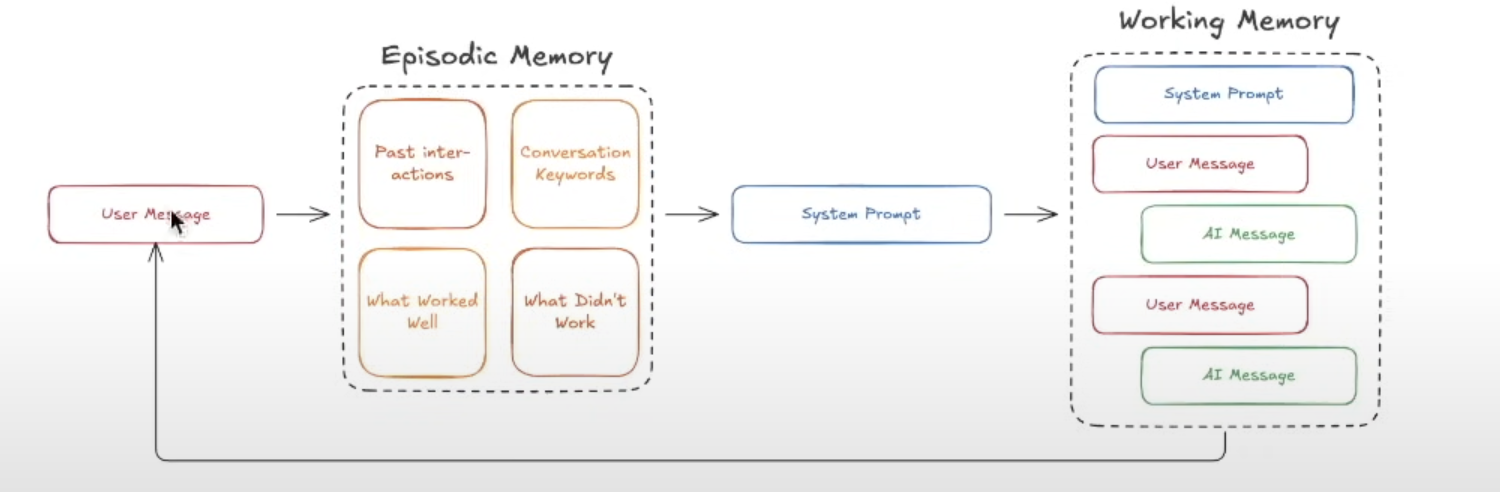

*Episodes, including what worked and what did not, are retrieved into the system prompt.*

That is exactly the fix for **Ticket 4**. DilSeTrips knows *facts* about Prasad but has no record of the *event*: the Manali trip in December. So for "where should we go next?", Manali still looks like a perfect match. We write the trip down as an episode, with what worked and what did not, then plan the next trip with and without it.

In [ ]:
episode_schema = {
    "title": "episode",
    "description": "A record of one experience",
    "type": "object",
    "properties": {
        "when": {"type": "string"}, "what_happened": {"type": "string"},
        "what_worked": {"type": "array", "items": {"type": "string"}},
        "what_did_not_work": {"type": "array", "items": {"type": "string"}},
    },
    "required": ["when", "what_happened", "what_worked", "what_did_not_work"],
}

debrief = ("We're back from Manali (20 to 23 December)! Old Manali was so quiet, Snow Valley Cottage was perfect and the veg "
           "food was great. But the flight to Chandigarh plus 8 hours in a taxi wrecked me, and two days of snow meant we "
           "couldn't go to Solang at all.")
episode = llm.with_structured_output(episode_schema).invoke("Record this trip as an episode for future planning:\n" + debrief)
print(json.dumps(episode, indent=2, ensure_ascii=False))

episode_text = (f"Trip episode ({episode['when']}): {episode['what_happened']} Worked: {'; '.join(episode['what_worked'])}. "
                f"Did not work: {'; '.join(episode['what_did_not_work'])}.")
store_memory("prasad", episode_text, "episodic", 4, 1.0, debrief[:60])

**Before you run it:** with the episode in memory, will DilSeTrips still suggest Manali? What will it keep from the Manali trip?

In [ ]:
next_trip = "Where should we go for our next short trip in February? One suggestion, three sentences, and say why."

# TODO: HW8 [Hard] - Every episode counts the same, however old. Should the Manali trip still stop DilSeTrips suggesting Manali
# in ten years? Add a way for old episodes to matter less, and a way for the couple to say "we'd happily go back".
def plan_with(kinds):
    def wanted(document):
        return (document.metadata["user_id"] == "prasad" and document.metadata["status"] == "active"
                and document.metadata["kind"] in kinds)
    remembered = ""
    for document in memory_store.similarity_search(next_trip, k=6, filter=wanted):
        remembered = remembered + "- " + document.page_content + "\n"
    reply = llm.invoke([SystemMessage(content="You are DilSeTrips. What you remember about this couple:\n" + remembered),
                        HumanMessage(content=next_trip)])
    return reply.text

print("Semantic memories only:\n", plan_with(["semantic"]), "\n")
print("Semantic + episodic memories:\n", plan_with(["semantic", "episodic"]))

With facts alone, a quiet hill station with vegetarian food is the obvious answer, so Manali (or somewhere very like it) comes back: Ticket 4. With the episode, the agent knows they have just been, and it can reuse what the episode taught: quiet places worked, long taxi rides and winter snow did not. That is **learning from experience** and **decision making** from the table above.

One caution, which is the "overfitting" challenge in Chapter 9: an episode should *inform* future choices, not dictate them. One bad taxi ride should not ban road trips forever.

### 8.3 Procedural memory: the muscle memory

Procedural memory stores **how to do things**: step-by-step methods, rules and routines, so the agent can perform a task again without relearning it. It is the agent's muscle memory. It is **skill-oriented** (how, not what), **implicit** (the agent just "knows how"), **reusable** across similar situations, and **sequential**. Examples: a robotic arm remembering how to pick up an object; a conversational AI remembering how to structure a polite reply; a self-driving car executing a lane change; a trading bot following its strategy.

Like human skills, it develops in phases: **acquisition** (learning a procedure through training, reinforcement or demonstration, such as an agent learning the moves that solve a maze), **consolidation** (refining it for speed and accuracy: finding shortcuts), **execution** (applying it automatically to new mazes) and **adaptation** (generalising it to related tasks, such as using one game's controls in a similar game).

In an LLM agent, much procedural memory lives in the model's weights. But some of it lives where you can change it: **the agent's own instructions**. When feedback reveals a better way of working, the agent can rewrite its procedure and keep it for next time. Here is DilSeTrips learning a procedure from Prasad's complaint about the weather tool, the one from last session.

In [ ]:
procedure = [
    "Greet the couple by name.",
    "Use the weather tool for weather questions.",
    "Suggest at most three options.",
]
feedback = ("You told us the weather for the week I was asking in, not for our December trip dates. "
            "And you keep giving me five hotel options when I asked for a short answer.")

rules_schema = {"title": "procedure", "description": "The agent's updated working rules", "type": "object",
                "properties": {"rules": {"type": "array", "items": {"type": "string"}}}, "required": ["rules"]}

current_rules = ""
for rule in procedure:
    current_rules = current_rules + "- " + rule + "\n"

updated = llm.with_structured_output(rules_schema).invoke(
    "These are your current working rules:\n" + current_rules +
    "\nA user gave this feedback:\n" + feedback +
    "\nRewrite the rules so this never happens again. Keep rules that are still right; make each rule short and specific."
)
procedure = updated["rules"]
print("Updated procedure:")
for rule in procedure:
    print(" -", rule)

The new rules usually say something like "the weather tool covers only the next 7 days; for later dates, say so" and "obey the user's requested length". Stored with the agent and loaded into its system prompt, this procedure now shapes every future conversation, for every user. That is the key difference from the other two kinds: semantic and episodic memories are usually *about a user*; procedural memory is *about how the agent works*. That also makes it the riskiest to change automatically. A bad rule spreads to everyone, so in production, procedural updates usually go through human review.

### 8.4 The three kinds compared

| Aspect | Semantic memory | Episodic memory | Procedural memory |
|---|---|---|---|
| Focus | Facts, concepts, general knowledge | Personal experiences and events | Skills, routines, how-to |
| Human analogy | A general knowledge base | A personal diary | Muscle memory |
| Data stored | Rules, definitions, relationships | Episodes with time, place and outcome | Step-by-step methods, learned behaviours |
| Retrieval style | Explicit: recalled when needed | Context-based: cued by the situation | Implicit: executed automatically |
| AI example | Medical facts for a health agent; "her partner is vegetarian" | A specific past conversation; the Manali trip | Navigating a maze; DilSeTrips' working rules |
| Use case | Reasoning and inference | Personalisation and learning from history | Performing tasks efficiently and repeatedly |

## 9. When memory goes wrong (Ticket 3)

Memory makes agents smarter, and it brings new risks. Picture an agent's memory as a filing cabinet with several drawers: the **working context** (the current prompt), **episodic memory** (records of past interactions), **semantic or long-term memory** (summaries and embeddings in a vector store) and **metadata and provenance** (timestamps, who said it, where it came from, whether the user consented). Problems come from both **technology** (how embeddings and retrieval behave) and **policy** (how long we keep data, what we summarise, what we delete).

### 9.1 Forgetting versus overfitting

**Forgetting** happens when retrieval favours recent chats and older facts fade or are "summarised away", like squeezing an essay into a tweet. **Overfitting** happens when the agent clings to one past fact and assumes it is always true. An AI career counsellor that forgets "I only want remote work" keeps suggesting office jobs; one that overfits on "I liked data science" keeps pushing data science after you have moved to product management. It is the friend who forgets your birthday but never lets go of something embarrassing you said years ago.

The causes: retrieval returning only the top few "similar" items, so older but important facts never surface; summaries that erase nuance; no freshness check. The fixes are the ones you built: **layered memory** (short-term context, long-term facts, raw records), a **score that balances similarity, recency and importance** (6.3), versioned updates when facts change (6.5), and occasionally **asking the user**: "Do you still prefer remote work?"

### 9.2 Hallucination amplification: Ticket 3

LLMs sometimes make things up. If a made-up "fact" is saved into memory, the agent repeats it as truth, builds new memories on it, and the error spreads. A healthcare assistant that once wrongly records "diabetes" biases every future diet, exercise and reminder suggestion. It is a photocopier copying a blurry page: each copy gets worse, and nobody notices the original was already wrong.

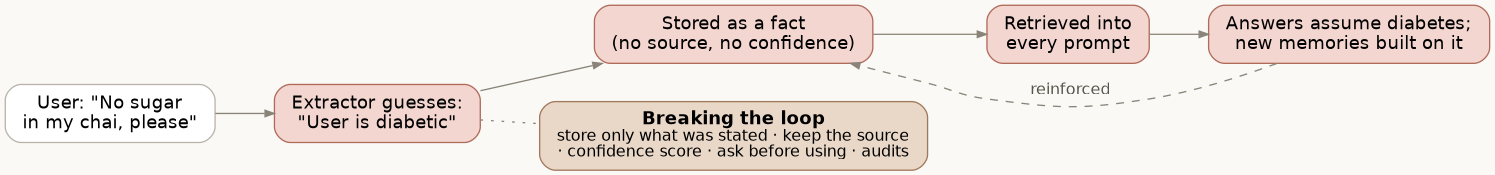

*A guess becomes a stored "fact", is retrieved into every prompt, and new memories build on it.*

This is exactly what happened to Kavya. Here is her message passed through two extractors: an eager one that tries to learn as much as possible about the user, and our careful one from 6.1.

**Before you run it:** what will the eager extractor store about Kavya's health?

In [ ]:
kavya_message = "Plan us a cosy weekend in Coorg. Oh, and no sugar in my chai at the homestay please, I've given it up."

eager_rules = ("You build a rich profile of the user for a travel concierge. Infer as much as you can about their health, "
               "lifestyle and preferences from what they say, so future suggestions are personalised.")

print("EAGER extractor stores:")
for memory in generate_memories("Kavya", kavya_message, rules=eager_rules):
    print(f"   conf {memory['confidence']:.2f}  {memory['text']}   <- \"{memory['source_quote']}\"")

# TODO: HW7 [Medium] - Each memory carries a source_quote. Write an audit that asks Gemini, with structured output, whether each
# quote actually supports its memory. Which of the eager extractor's memories fail, and what should happen to them?
print("\nCAREFUL extractor stores:")
for memory in generate_memories("Kavya", kavya_message):
    print(f"   conf {memory['confidence']:.2f}  {memory['text']}   <- \"{memory['source_quote']}\"")

The eager extractor often writes something like "Kavya may be diabetic" or "Kavya is health-conscious and avoids sugar for medical reasons": a guess, stored as a fact. Every future prompt would then carry it, and every suggestion would be "diabetic-friendly": Ticket 3. The careful extractor stores what she actually said: she has given up sugar in her chai.

Look at the source quote beside each memory. For the guess, the quote ("no sugar in my chai") does not support the stored text ("may be diabetic"). That mismatch is exactly what an automated **memory audit** can check for (homework 7).

The fixes for hallucination amplification:

- **Store provenance**: the agent should know where every memory came from (our `source_quote`).
- **Flag low-trust information** instead of storing it as fact (our `confidence`, and the "unconfirmed: ask first" note in 6.4).
- **Run memory audits**: periodically check memories against their sources, or ask the user to confirm.
- **Use version control**: when a mistake is found, mark it invalid and roll back (our `status` and `version` fields).

### 9.3 Privacy and security of stored interactions

Agents store chats, embeddings and metadata, and even embeddings are not harmless: research has shown that text can sometimes be partly reconstructed from its embedding. A banking chatbot that stores full transcripts with card numbers, unencrypted, turns one database breach into a financial disaster. It is a hospital leaving patient files unlocked at the front desk: the doctors may be honest, but the lack of locks makes it unsafe.

The fixes: **encrypt** everything at rest and in transit; **control access**, so not every part of the system can read every memory; give users the **right to be forgotten** (the hard delete in 6.6); and **log every access**: who read what, and when. Two of these we can show directly: personal data should never be extracted in the first place, and one user's memories must never reach another user.

In [ ]:
risky_message = ("Book the Coorg homestay on my card 4111 1111 1111 1111, OTP is 482913. My phone is 98200 12345. "
                 "We prefer a room with a balcony.")
print("What the careful extractor keeps from a message full of personal data:")
for memory in generate_memories("Kavya", risky_message):
    print("   ", memory["text"])

# Cross-user isolation: Prasad's queries must never return another user's memories
store_memory("kavya", "Kavya has given up sugar in her chai.", "semantic", 2, 1.0, "no sugar in my chai")

def prasads_active_memories(document):
    return document.metadata["user_id"] == "prasad" and document.metadata["status"] == "active"

leaked = 0
for document in memory_store.similarity_search("food and drink preferences", k=10, filter=prasads_active_memories):
    if document.metadata["user_id"] != "prasad":
        leaked = leaked + 1
print(f"\nOther users' memories returned to Prasad: {leaked}")

The extractor keeps the balcony preference and drops the card number, OTP and phone number. And the user filter returns none of Kavya's memories to Prasad. Here that filter is one line of Python; in a production vector database it is usually a **namespace** per user or tenant (Pinecone has these), so isolation does not depend on every query remembering to filter. Note that the extractor's rule is a defence, not a guarantee: sensitive data should also be redacted by code before it reaches any model or store.

### 9.4 Scaling memory to thousands of agents

Fixes that work for one agent strain at **10,000 agents** storing billions of memories. It is the difference between a bookshelf and a city library: storage, speed and organisation all become hard. Billions of embeddings cost real money to store; retrieval must still take well under a second; and agents must never mix up one user's memories with another's. A company running 10,000 support agents must retrieve the right context in under a second while guaranteeing user A's data never reaches user B. Think of a huge hotel: every guest has a private keycard (private memory), there is a shared cafeteria (a shared knowledge base), and if the keys get mixed up, chaos follows.

The fixes: **hot and cold storage** (recent memories in fast storage, older ones in slower, cheaper storage), **caching** frequent lookups, **per-user namespaces**, and **monitoring** speed, accuracy and growth.

| Challenge | What happens | Why it matters | Example | Fixes |
|---|---|---|---|---|
| Forgetting versus overfitting | Old facts fade; or one old fact dominates | Personalisation becomes incomplete or stubborn | A career counsellor forgets "remote only", or keeps pushing data science | Layered memory; balanced scoring; versioning; confirm with the user |
| Hallucination amplification | Guesses are stored as facts and reinforced | Errors spread through every future answer | A health assistant wrongly records "diabetes" | Provenance; confidence flags; audits; rollback |
| Privacy and security | Stored chats, embeddings and metadata can leak | Legal, financial and trust damage | A banking bot storing card numbers unencrypted | Don't extract sensitive data; encrypt; access control; hard delete; audit logs |
| Scaling | Billions of memories across thousands of agents | Must stay fast, cheap and isolated | 10,000 support agents, sub-second retrieval | Hot and cold storage; caching; namespaces; monitoring |

## 10. Conclusions

**Memory turns agents from reactive responders into adaptive systems** that recall, learn and personalise. The same model gave Riya and Dr. Sen two different answers because of three saved facts.

**Traditional AI relied on static, pre-programmed memory; agentic AI uses dynamic, evolving memory.** That flexibility is powerful, and it is also how a guess about diabetes can become a "fact".

**Different kinds of memory play different roles.** Short-term memory, the context window, holds the current conversation and forgets by overflow. Long-term memory persists, as semantic (facts), episodic (experiences) and procedural (how-to) memory.

**Vector databases and knowledge graphs make storage and retrieval work**, each with trade-offs: vectors find what looks related; graphs follow precise connections but need careful entity resolution.

**Building memory means balancing benefits against risks**: forgetting, overfitting, hallucinations, privacy and scale.

### The five tickets, closed

| Ticket | Cause | Fix you built |
|---|---|---|
| 1. Vegetarian forgotten after 20 messages | Overflow forgetting in a small context window | Summary plus buffer, or entity memory, keeping critical facts (5.5) |
| 2. Asks where I live every time | No long-term memory across sessions | Generate, store, retrieve, integrate (6.1 to 6.4) |
| 3. "Diabetic" from "no sugar in my chai" | An eager extractor stored a guess as a fact | Explicit-only extraction with source quotes and confidence (9.2) |
| 4. Suggests Manali after we went there | Facts but no record of the event | Episodic memory of the trip, with what worked and what did not (8.2) |
| 5. Delete everything about me | Memory without a deletion path | Hard delete of text and embeddings (6.6), with cascading as homework |

And the idea underneath all of them: **the model remembered nothing at any point.** Every fix was a decision in your code about what to write down, how to label it, and what to put back into the prompt. No framework makes those decisions for you, and none checks whether a stored memory is true.

## 11. Homework

Items marked in the code have a `# TODO: HWn` comment at the exact line.

| # | Level | Task | Where |
|---|---|---|---|
| HW1 | Easy | Tune the retrieval score | `retrieve_memories`, 6.3 |
| HW2 | Medium | Protect critical facts from summaries | 5.5 |
| HW3 | Medium | Move memory to Pinecone with namespaces | 6.2 |
| HW4 | Medium | Handle bad replacement decisions | 6.5 |
| HW5 | Hard | Cascading deletes | 6.6 |
| HW6 | Easy | Tune the forgetting thresholds | Chapter 7 |
| HW7 | Medium | An automated memory audit | 9.2 |
| HW8 | Hard | Stop old episodes dominating | 8.2 |

**HW2 [Medium]: protect critical facts from summaries.** Add "Neha has a peanut allergy" to turn 1 of the Amritsar conversation and re-run 5.5. Does the summary keep it word for word, or soften it to "food restrictions"? Design a rule so that memories with importance 5 are always passed verbatim, never summarised.

**HW3 [Medium]: Pinecone with namespaces.** Move `memory_store` into your Pinecone index from earlier sessions, using one namespace per user. Read the embedding dimension from the index instead of typing it. Is the user filter in `retrieve_memories` still needed? Why might you keep it anyway?

**HW7 [Medium]: memory audit.** Write an audit that sends each stored memory and its `source_quote` to Gemini with structured output: does the quote support the memory, yes or no? Run it on the eager extractor's output from 9.2. Which memories fail? What should happen to them?

**HW8 [Hard]: old episodes.** In ten years, should the Manali episode still stop DilSeTrips suggesting Manali? Add a decay to episodic memories so they influence less as they age, and a way for the user to say "we'd go back".

**Suggested order.** HW1 and HW6 first (just numbers). Then HW2, which is about short-term memory. Then HW4 and HW7, both about keeping long-term memory correct. HW5 and HW8 need more design. HW3 connects to your Pinecone work; do it last.

## 12. Quick reference

| Idea | One line | Code |
|---|---|---|
| The rule | The model remembers nothing; your code writes and reads memory | everywhere |
| Short-term memory | The context window; forgets by overflow | the message list; `trim_messages` |
| Buffer, window, summary, summary + buffer, entity | Five ways to keep a conversation | 5.5 |
| Long-term memory | Persists across sessions | `memory_store` with metadata |
| Generate | Extract explicit facts with source and confidence | `generate_memories` |
| Retrieve | Filter, similarity, re-rank by recency and importance | `retrieve_memories` |
| Integrate | Put memories in the prompt with provenance | `memory_context` |
| Update | Version, mark old superseded | `update_memory` |
| Delete | Soft (flag) or hard (text and embedding) | `memory_store.delete(ids=...)` |
| Forgetting strategies | Periodical, history-based, combined | Chapter 7 |
| Semantic memory | Facts | triples; fact memories |
| Episodic memory | Experiences: what happened, what worked | `episode_schema` |
| Procedural memory | How the agent works | the updated `procedure` |
| Knowledge graph | Entities as nodes, relations as edges | `objects_of`, `subjects_with` |
| Hallucination amplification | A stored guess becomes a "fact" | eager versus careful extractor |